# V3 SAC Controller Benchmarking

This notebook benchmarks the trained V3 Soft Actor-Critic (SAC) controller
against two reference operating strategies:

1. **EnergyPlus Baseline** – original simulated chilled-water operation.
2. **Minimum-Feasible Engineering Benchmark** – minimum flow required by the
   V1 ETS physics model to satisfy cooling demand at the design ΔT.
3. **SAC Controller** – trained V3 SAC controller.

All controllers are evaluated over the same held-out test period used during
the final V3 SAC evaluation.

The principal comparison metrics are:

- Cooling requirement
- Cooling delivery
- Unmet cooling
- Pump energy
- Chilled-water flow
- ETS ΔT
- Pump-energy saving relative to the EnergyPlus baseline

The EnergyPlus baseline is obtained directly from the EnergyPlus simulation.
The minimum-feasible and SAC controllers are evaluated using the V1 ETS
physics model.

Cell 2 — Imports

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

from stable_baselines3 import SAC

from ets_model_v1 import (
    ETSModelV1,
    calibrate_from_energyplus,
    COL_Q_COIL,
    COL_T_SUPPLY,
    COL_T_RETURN,
    COL_COIL_FLOW,
    COL_PUMP_FLOW,
    COL_PUMP_POWER,
)

from ets_gym_v2 import ETSGymV2

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Imports completed successfully.")

Imports completed successfully.


Cell 3 — Configuration

In [8]:
# ---------------------------------------------------------
# File locations
# ---------------------------------------------------------

PROJECT_DIR = Path(
    "/Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE"
)

CSV_PATH = PROJECT_DIR / "eplusout.csv"

V3_OUTPUT = PROJECT_DIR / "V3_sac_training_stage/src/v3_sac_output"

METRICS_PATH = V3_OUTPUT / "sac_test_metrics.json"

BEST_MODEL_PATH = (
    V3_OUTPUT
    / "best_model"
    / "best_model.zip"
)

BENCHMARK_OUTPUT = (
    PROJECT_DIR
    / "v3_benchmark_output"
)

BENCHMARK_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)


# ---------------------------------------------------------
# Experiment configuration
# ---------------------------------------------------------

TIMESTEP_HOURS = 0.25
ACTIVE_LOAD_W = 10.0
DESIGN_DELTA_T_C = 4.0


print("CSV:", CSV_PATH)
print("Metrics:", METRICS_PATH)
print("SAC model:", BEST_MODEL_PATH)
print("Output:", BENCHMARK_OUTPUT)

CSV: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/eplusout.csv
Metrics: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/V3_sac_training_stage/src/v3_sac_output/sac_test_metrics.json
SAC model: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/V3_sac_training_stage/src/v3_sac_output/best_model/best_model.zip
Output: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/v3_benchmark_output


Cell 4 — Check required files

In [9]:
required_files = {
    "EnergyPlus CSV": CSV_PATH,
    "V3 metrics": METRICS_PATH,
    "SAC best model": BEST_MODEL_PATH,
}

for name, path in required_files.items():
    exists = path.exists()

    print(
        f"{name:20s}: "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    if not exists:
        print(f"    {path}")

EnergyPlus CSV      : FOUND
V3 metrics          : FOUND
SAC best model      : FOUND


Cell 5 — Load EnergyPlus data

In [10]:
df = pd.read_csv(CSV_PATH)

print("EnergyPlus dataset loaded.")
print("Rows   :", len(df))
print("Columns:", len(df.columns))

df.head()

EnergyPlus dataset loaded.
Rows   : 35232
Columns: 27


,Date/Time,Environment:Site Outdoor Air Drybulb Temperature [C](TimeStep),Environment:Site Outdoor Air Relative Humidity [%](TimeStep),Environment:Site Diffuse Solar Radiation Rate per Area [W/m2](TimeStep),Environment:Site Direct Solar Radiation Rate per Area [W/m2](TimeStep),Environment:Site Day Type Index [](TimeStep),MAIN ZONE:Zone People Occupant Count [](TimeStep),MAIN ZONE:Zone Mean Air Temperature [C](TimeStep),MAIN ZONE:Zone Air Relative Humidity [%](TimeStep),MAIN ZONE:Zone Air System Sensible Heating Energy [J](TimeStep),MAIN ZONE:Zone Air System Sensible Cooling Energy [J](TimeStep),MAIN ZONE:Zone Air System Sensible Heating Rate [W](TimeStep),MAIN ZONE:Zone Air System Sensible Cooling Rate [W](TimeStep),MAIN ZONE:Zone Thermostat Heating Setpoint Temperature [C](TimeStep),MAIN ZONE:Zone Thermostat Cooling Setpoint Temperature [C](TimeStep),OCCUPANCY SCHEDULE:Schedule Value [](TimeStep),MAIN ZONE FCU COOLING COIL:Cooling Coil Total Cooling Rate [W](TimeStep),CHW CIRC PUMP:Pump Electricity Rate [W](TimeStep),CHW CIRC PUMP:Pump Mass Flow Rate [kg/s](TimeStep),CHW SUPPLY OUTLET NODE:System Node Temperature [C](TimeStep),MAIN ZONE FCU COOLING COIL WATER INLET:System Node Temperature [C](TimeStep),MAIN ZONE FCU COOLING COIL WATER INLET:System Node Mass Flow Rate [kg/s](TimeStep),MAIN ZONE FCU COOLING COIL WATER OUTLET:System Node Temperature [C](TimeStep),CHW DEMAND OUTLET NODE:System Node Temperature [C](TimeStep),Electricity:HVAC [J](TimeStep),Electricity:Facility [J](TimeStep),Cooling:Electricity [J](TimeStep)
0,01/21 00:15:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.069028,2.722181e+06,0.0,3024.645550,0.0,20.0,24.0,0.0,0.0,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722181e+06,2.884181e+06,0.0
1,01/21 00:30:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.176813,2.722199e+06,0.0,3024.665394,0.0,20.0,24.0,0.0,0.0,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722199e+06,2.884199e+06,0.0
2,01/21 00:45:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.284512,2.722216e+06,0.0,3024.684651,0.0,20.0,24.0,0.0,0.0,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722216e+06,2.884216e+06,0.0
3,01/21 01:00:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.392143,2.722233e+06,0.0,3024.703337,0.0,20.0,24.0,0.0,0.0,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722233e+06,2.884233e+06,0.0
4,01/21 01:15:00,11.0,99.999979,0.0,0.0,10.0,0.0,20.0,99.499702,2.722249e+06,0.0,3024.721470,0.0,20.0,24.0,0.0,0.0,0.0,0.0,7.0,7.0,0.0,7.0,7.0,2.722249e+06,2.884249e+06,0.0


Cell 6 — Load exact V3 test definition

In [11]:
with open(
    METRICS_PATH,
    "r",
    encoding="utf-8"
) as f:
    original_v3_metrics = json.load(f)


TEST_START_INDEX = int(
    original_v3_metrics["test_start_index"]
)

TEST_STEPS = int(
    original_v3_metrics["test_steps"]
)

TEST_FINAL_INDEX = (
    TEST_START_INDEX
    + TEST_STEPS
    - 1
)


print("V3 held-out test configuration")
print("-" * 45)

print(
    f"Start index : {TEST_START_INDEX}"
)

print(
    f"Final index : {TEST_FINAL_INDEX}"
)

print(
    f"Transitions : {TEST_STEPS}"
)

print(
    f"Dataset rows: {len(df)}"
)

V3 held-out test configuration
---------------------------------------------
Start index : 28128
Final index : 35230
Transitions : 7103
Dataset rows: 35232


Cell 7 — Validate test range

In [12]:
assert TEST_START_INDEX >= 0
assert TEST_STEPS > 0

assert (
    TEST_FINAL_INDEX < len(df) - 1
), "Test range exceeds the final usable dataset transition."

print("Test range validation: PASS")

Test range validation: PASS


Cell 8 — Calibrate V1 ETS model

In [13]:
ets_config = calibrate_from_energyplus(
    df,
    DESIGN_DELTA_T_C
)

ets_model = ETSModelV1(
    ets_config
)


print("V1 ETS calibration")
print("-" * 45)

print(
    f"Maximum CHW flow : "
    f"{ets_config.max_flow_kg_s:.6f} kg/s"
)

print(
    f"Pump coefficient : "
    f"{ets_config.pump_w_per_kg_s:.6f} W/(kg/s)"
)

print(
    f"Design Delta-T   : "
    f"{ets_config.design_delta_t_c:.3f} °C"
)

V1 ETS calibration
---------------------------------------------
Maximum CHW flow : 0.907702 kg/s
Pump coefficient : 255.557654 W/(kg/s)
Design Delta-T   : 4.000 °C


Cell 9 — EnergyPlus baseline

In [14]:
test_df = df.iloc[
    TEST_START_INDEX:
    TEST_START_INDEX + TEST_STEPS
].copy()


required = (
    test_df[COL_Q_COIL]
    .astype(float)
    .clip(lower=0.0)
)

flow = (
    test_df[COL_COIL_FLOW]
    .astype(float)
    .clip(lower=0.0)
)

pump_power = (
    test_df[COL_PUMP_POWER]
    .astype(float)
    .clip(lower=0.0)
)

supply_temp = (
    test_df[COL_T_SUPPLY]
    .astype(float)
)

return_temp = (
    test_df[COL_T_RETURN]
    .astype(float)
)

delta_t = (
    return_temp
    - supply_temp
)


baseline_df = pd.DataFrame({
    "dataset_index": np.arange(
        TEST_START_INDEX,
        TEST_START_INDEX + TEST_STEPS
    ),

    "controller": "EnergyPlus Baseline",

    "q_required_w":
        required.to_numpy(),

    "q_delivered_w":
        required.to_numpy(),

    # Not directly comparable with V1/V2 unmet cooling.
    "q_unmet_w":
        np.nan,

    "flow_command":
        np.nan,

    "flow_kg_s":
        flow.to_numpy(),

    "supply_temp_c":
        supply_temp.to_numpy(),

    "return_temp_c":
        return_temp.to_numpy(),

    "delta_t_c":
        delta_t.to_numpy(),

    "pump_power_w":
        pump_power.to_numpy(),
})


print(
    "EnergyPlus baseline transitions:",
    len(baseline_df)
)

baseline_df.head()

EnergyPlus baseline transitions: 7103


,dataset_index,controller,q_required_w,q_delivered_w,q_unmet_w,flow_command,flow_kg_s,supply_temp_c,return_temp_c,delta_t_c,pump_power_w
0,28128,EnergyPlus Baseline,4665.024976,4665.024976,NaN,NaN,0.740162,7.0,8.502362,1.502362,189.147705
1,28129,EnergyPlus Baseline,4550.333013,4550.333013,NaN,NaN,0.725650,7.0,8.494732,1.494732,185.439187
2,28130,EnergyPlus Baseline,4439.335538,4439.335538,NaN,NaN,0.711553,7.0,8.487162,1.487162,181.836523
3,28131,EnergyPlus Baseline,4330.351405,4330.351405,NaN,NaN,0.697682,7.0,8.479494,1.479494,178.291790
4,28132,EnergyPlus Baseline,4222.130554,4222.130554,NaN,NaN,0.683897,7.0,8.471595,1.471595,174.769069


Cell 10 — Quick baseline sanity check

In [15]:
baseline_active = baseline_df[
    baseline_df["q_required_w"] > ACTIVE_LOAD_W
]

baseline_required_kwh = (
    baseline_df["q_required_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)

baseline_pump_kwh = (
    baseline_df["pump_power_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)


print("EnergyPlus test-period baseline")
print("-" * 45)

print(
    f"Required cooling : "
    f"{baseline_required_kwh:.4f} kWh_th"
)

print(
    f"Pump energy      : "
    f"{baseline_pump_kwh:.4f} kWh"
)

print(
    f"Mean active flow : "
    f"{baseline_active['flow_kg_s'].mean():.4f} kg/s"
)

print(
    f"Mean active ΔT   : "
    f"{baseline_active['delta_t_c'].mean():.4f} °C"
)

print(
    f"Median active ΔT : "
    f"{baseline_active['delta_t_c'].median():.4f} °C"
)

print(
    f"Active steps     : "
    f"{len(baseline_active)}"
)

EnergyPlus test-period baseline
---------------------------------------------
Required cooling : 5690.0845 kWh_th
Pump energy      : 205.1301 kWh
Mean active flow : 0.4963 kg/s
Mean active ΔT   : 1.5129 °C
Median active ΔT : 1.4321 °C
Active steps     : 6469


Cell 11 — Minimum-feasible controller

In [16]:
minimum_rows = []

for dataset_index in range(
    TEST_START_INDEX,
    TEST_START_INDEX + TEST_STEPS
):

    row = df.iloc[dataset_index]

    q_required = max(
        float(row[COL_Q_COIL]),
        0.0
    )

    supply_temp = float(
        row[COL_T_SUPPLY]
    )

    command = (
        ets_model.minimum_feasible_command(
            q_required
        )
    )

    result = ets_model.step(
        q_required_w=q_required,
        supply_temp_c=supply_temp,
        flow_command=command,
    )

    minimum_rows.append({
        "dataset_index":
            dataset_index,

        "controller":
            "Minimum Feasible",

        "q_required_w":
            result.q_required_w,

        "q_delivered_w":
            result.q_delivered_w,

        "q_unmet_w":
            result.q_unmet_w,

        "flow_command":
            result.flow_command,

        "flow_kg_s":
            result.flow_kg_s,

        "supply_temp_c":
            result.supply_temp_c,

        "return_temp_c":
            result.return_temp_c,

        "delta_t_c":
            result.delta_t_c,

        "pump_power_w":
            result.pump_power_w,
    })


minimum_df = pd.DataFrame(
    minimum_rows
)


print(
    "Minimum-feasible transitions:",
    len(minimum_df)
)

minimum_df.head()

Minimum-feasible transitions: 7103


,dataset_index,controller,q_required_w,q_delivered_w,q_unmet_w,flow_command,flow_kg_s,supply_temp_c,return_temp_c,delta_t_c,pump_power_w
0,28128,Minimum Feasible,4665.024976,4665.024976,0.0,0.307379,0.279009,7.0,11.0,4.0,71.302801
1,28129,Minimum Feasible,4550.333013,4550.333013,0.0,0.299822,0.272149,7.0,11.0,4.0,69.549787
2,28130,Minimum Feasible,4439.335538,4439.335538,0.0,0.292508,0.265510,7.0,11.0,4.0,67.853240
3,28131,Minimum Feasible,4330.351405,4330.351405,0.0,0.285327,0.258992,7.0,11.0,4.0,66.187467
4,28132,Minimum Feasible,4222.130554,4222.130554,0.0,0.278197,0.252520,7.0,11.0,4.0,64.533360


Cell 12 — Minimum-feasible sanity check

In [17]:
minimum_active = minimum_df[
    minimum_df["q_required_w"] > ACTIVE_LOAD_W
]

minimum_pump_kwh = (
    minimum_df["pump_power_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)

minimum_unmet_kwh = (
    minimum_df["q_unmet_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)


print("Minimum-feasible benchmark")
print("-" * 45)

print(
    f"Pump energy      : "
    f"{minimum_pump_kwh:.4f} kWh"
)

print(
    f"Unmet cooling    : "
    f"{minimum_unmet_kwh:.6f} kWh_th"
)

print(
    f"Mean active flow : "
    f"{minimum_active['flow_kg_s'].mean():.4f} kg/s"
)

print(
    f"Mean active ΔT   : "
    f"{minimum_active['delta_t_c'].mean():.4f} °C"
)

print(
    f"Median active ΔT : "
    f"{minimum_active['delta_t_c'].median():.4f} °C"
)

Minimum-feasible benchmark
---------------------------------------------
Pump energy      : 86.9704 kWh
Unmet cooling    : 0.000000 kWh_th
Mean active flow : 0.2104 kg/s
Mean active ΔT   : 4.0000 °C
Median active ΔT : 4.0000 °C


Cell 13 — Load trained SAC

In [18]:
sac_model = SAC.load(
    str(BEST_MODEL_PATH)
)

print(
    "Loaded SAC model:",
    BEST_MODEL_PATH
)

Loaded SAC model: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/V3_sac_training_stage/src/v3_sac_output/best_model/best_model.zip


Cell 14 — Create SAC test environment

In [19]:
sac_env = ETSGymV2(
    str(CSV_PATH),
    random_start=False,
)

obs, reset_info = sac_env.reset(
    options={
        "start_index": TEST_START_INDEX
    }
)

# Extend the normal 24-hour episode so that the
# complete held-out test region is evaluated.
sac_env.episode_steps = TEST_STEPS


print(
    "SAC evaluation start index:",
    TEST_START_INDEX
)

print(
    "Requested transitions:",
    TEST_STEPS
)

print(
    "Observation shape:",
    obs.shape
)

SAC evaluation start index: 28128
Requested transitions: 7103
Observation shape: (16,)


Cell 15 — Sequential SAC evaluation

In [20]:
sac_rows = []

done = False

while not done:

    action, _ = sac_model.predict(
        obs,
        deterministic=True
    )

    (
        obs,
        reward,
        terminated,
        truncated,
        info,
    ) = sac_env.step(action)

    sac_rows.append({
        "dataset_index":
            info["dataset_index"],

        "controller":
            "SAC",

        "q_required_w":
            info["q_required_w"],

        "q_delivered_w":
            info["q_delivered_w"],

        "q_unmet_w":
            info["q_unmet_w"],

        "flow_command":
            info["flow_command"],

        "flow_kg_s":
            info["flow_kg_s"],

        "supply_temp_c":
            info["supply_temp_c"],

        "return_temp_c":
            info["return_temp_c"],

        "delta_t_c":
            info["delta_t_c"],

        "pump_power_w":
            info["pump_power_w"],

        "reward":
            reward,
    })

    done = terminated or truncated


sac_df = pd.DataFrame(
    sac_rows
)


print(
    "SAC transitions:",
    len(sac_df)
)

sac_df.head()

SAC transitions: 7103


,dataset_index,controller,q_required_w,q_delivered_w,q_unmet_w,flow_command,flow_kg_s,supply_temp_c,return_temp_c,delta_t_c,pump_power_w,reward
0,28128,SAC,4665.024976,4665.024976,0.0,0.313444,0.284514,7.0,10.922605,3.922605,72.709639,-0.383486
1,28129,SAC,4550.333013,4550.333013,0.0,0.334112,0.303274,7.0,10.589476,3.589476,77.504103,-0.541441
2,28130,SAC,4439.335538,4439.335538,0.0,0.325473,0.295433,7.0,10.594867,3.594867,75.500138,-0.528904
3,28131,SAC,4330.351405,4330.351405,0.0,0.317362,0.288070,7.0,10.596244,3.596244,73.618434,-0.520051
4,28132,SAC,4222.130554,4222.130554,0.0,0.309358,0.280805,7.0,10.597088,3.597088,71.761783,-0.511614


Cell 16 — Calculate SAC metrics

In [21]:
sac_active = sac_df[
    sac_df["q_required_w"] > ACTIVE_LOAD_W
]

sac_required_kwh = (
    sac_df["q_required_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)

sac_delivered_kwh = (
    sac_df["q_delivered_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)

sac_unmet_kwh = (
    sac_df["q_unmet_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)

sac_pump_kwh = (
    sac_df["pump_power_w"].sum()
    * TIMESTEP_HOURS
    / 1000
)

sac_delivery_pct = (
    100
    * sac_delivered_kwh
    / sac_required_kwh
)


sac_metrics = {
    "required_cooling_kwh_th":
        sac_required_kwh,

    "delivered_cooling_kwh_th":
        sac_delivered_kwh,

    "unmet_cooling_kwh_th":
        sac_unmet_kwh,

    "delivery_fraction_pct":
        sac_delivery_pct,

    "pump_energy_kwh":
        sac_pump_kwh,

    "mean_delta_t_c_active":
        sac_active["delta_t_c"].mean(),

    "median_delta_t_c_active":
        sac_active["delta_t_c"].median(),

    "mean_flow_command_active":
        sac_active["flow_command"].mean(),
}


pd.DataFrame(
    [sac_metrics]
).T.rename(
    columns={0: "Benchmark Result"}
)

,Benchmark Result
required_cooling_kwh_th,5690.084457
delivered_cooling_kwh_th,5687.792791
unmet_cooling_kwh_th,2.291666
delivery_fraction_pct,99.959725
pump_energy_kwh,112.943898
mean_delta_t_c_active,3.030161
median_delta_t_c_active,3.311896
mean_flow_command_active,0.284828


Cell 17 — Critical reproduction test

In [22]:
checks = [
    "required_cooling_kwh_th",
    "delivered_cooling_kwh_th",
    "unmet_cooling_kwh_th",
    "delivery_fraction_pct",
    "pump_energy_kwh",
    "mean_delta_t_c_active",
    "median_delta_t_c_active",
    "mean_flow_command_active",
]


comparison_rows = []

for metric in checks:

    expected = float(
        original_v3_metrics[metric]
    )

    actual = float(
        sac_metrics[metric]
    )

    difference = abs(
        actual - expected
    )

    comparison_rows.append({
        "Metric":
            metric,

        "Original V3":
            expected,

        "Benchmark":
            actual,

        "Absolute Difference":
            difference,

        "Status":
            "PASS"
            if difference < 1e-4
            else "FAIL"
    })


reproduction_df = pd.DataFrame(
    comparison_rows
)

reproduction_df

,Metric,Original V3,Benchmark,Absolute Difference,Status
0,required_cooling_kwh_th,5690.084457,5690.084457,8.185452e-12,PASS
1,delivered_cooling_kwh_th,5687.792791,5687.792791,5.456968e-12,PASS
2,unmet_cooling_kwh_th,2.291666,2.291666,0.000000e+00,PASS
3,delivery_fraction_pct,99.959725,99.959725,4.263256e-14,PASS
4,pump_energy_kwh,112.943898,112.943898,4.121148e-13,PASS
5,mean_delta_t_c_active,3.030161,3.030161,0.000000e+00,PASS
6,median_delta_t_c_active,3.311896,3.311896,0.000000e+00,PASS
7,mean_flow_command_active,0.284828,0.284828,0.000000e+00,PASS


Final Result

In [23]:
assert (
    reproduction_df["Status"] == "PASS"
).all(), (
    "SAC benchmark does not reproduce the "
    "original V3 evaluation."
)

print(
    "SAC V3 reproduction validation: PASS"
)

SAC V3 reproduction validation: PASS


Section 10 — Final Controller KPI Comparison

# 10. Final Controller KPI Comparison

This section performs the final quantitative comparison of the three V3
operating strategies over the identical held-out test period:

1. **EnergyPlus Baseline** – the original simulated chilled-water operation.
2. **Minimum-Feasible Engineering Benchmark** – the theoretical minimum flow
   required by the V1 ETS model to satisfy the cooling requirement at the
   4°C design ΔT.
3. **SAC Controller** – the trained V3 Soft Actor-Critic controller.

The comparison considers cooling delivery, pumping energy, chilled-water flow
and ETS ΔT. Flow and ΔT statistics are calculated during active cooling
periods, defined as cooling requirement greater than 10 W.

The minimum-feasible strategy is treated as an engineering reference rather
than a learned controller. The 4°C ΔT is the design benchmark used by the
current EnergyPlus/V1 model and is not interpreted as a regulatory minimum.

In [24]:
def controller_summary(result_df, baseline=False):

    active = result_df[
        result_df["q_required_w"] > ACTIVE_LOAD_W
    ].copy()

    required_kwh = (
        result_df["q_required_w"].sum()
        * TIMESTEP_HOURS
        / 1000
    )

    delivered_kwh = (
        result_df["q_delivered_w"].sum()
        * TIMESTEP_HOURS
        / 1000
    )

    pump_kwh = (
        result_df["pump_power_w"].sum()
        * TIMESTEP_HOURS
        / 1000
    )

    if baseline:
        unmet_kwh = np.nan
        delivery_pct = np.nan
    else:
        unmet_kwh = (
            result_df["q_unmet_w"].sum()
            * TIMESTEP_HOURS
            / 1000
        )

        delivery_pct = (
            100.0 * delivered_kwh / required_kwh
            if required_kwh > 0
            else 100.0
        )

    return {
        "Controller":
            result_df["controller"].iloc[0],

        "Transitions":
            len(result_df),

        "Active Transitions":
            len(active),

        "Required Cooling (kWh_th)":
            required_kwh,

        "Delivered Cooling (kWh_th)":
            delivered_kwh,

        "Unmet Cooling (kWh_th)":
            unmet_kwh,

        "Delivery (%)":
            delivery_pct,

        "Pump Energy (kWh)":
            pump_kwh,

        "Mean Active Flow (kg/s)":
            active["flow_kg_s"].mean(),

        "Median Active Flow (kg/s)":
            active["flow_kg_s"].median(),

        "Maximum Active Flow (kg/s)":
            active["flow_kg_s"].max(),

        "Mean Active ΔT (°C)":
            active["delta_t_c"].mean(),

        "Median Active ΔT (°C)":
            active["delta_t_c"].median(),

        "Minimum Active ΔT (°C)":
            active["delta_t_c"].min(),

        "Maximum Active ΔT (°C)":
            active["delta_t_c"].max(),

        "Mean Flow Command":
            (
                active["flow_command"].mean()
                if active["flow_command"].notna().any()
                else np.nan
            ),
    }


baseline_summary = controller_summary(
    baseline_df,
    baseline=True
)

minimum_summary = controller_summary(
    minimum_df
)

sac_summary = controller_summary(
    sac_df
)


kpi_df = pd.DataFrame([
    baseline_summary,
    minimum_summary,
    sac_summary,
])


baseline_pump = baseline_summary[
    "Pump Energy (kWh)"
]


kpi_df["Pump Saving vs Baseline (%)"] = (
    100.0
    * (
        baseline_pump
        - kpi_df["Pump Energy (kWh)"]
    )
    / baseline_pump
)

kpi_df.loc[
    kpi_df["Controller"] == "EnergyPlus Baseline",
    "Pump Saving vs Baseline (%)"
] = 0.0


kpi_df.round(4)

,Controller,Transitions,Active Transitions,Required Cooling (kWh_th),Delivered Cooling (kWh_th),Unmet Cooling (kWh_th),Delivery (%),Pump Energy (kWh),Mean Active Flow (kg/s),Median Active Flow (kg/s),Maximum Active Flow (kg/s),Mean Active ΔT (°C),Median Active ΔT (°C),Minimum Active ΔT (°C),Maximum Active ΔT (°C),Mean Flow Command,Pump Saving vs Baseline (%)
0,EnergyPlus Baseline,7103,6469,5690.0845,5690.0845,NaN,NaN,205.1301,0.4963,0.5054,0.9076,1.5129,1.4321,0.1094,2.8927,NaN,0.0000
1,Minimum Feasible,7103,6469,5690.0845,5690.0845,0.0000,100.0000,86.9704,0.2104,0.1878,0.6442,4.0000,4.0000,4.0000,4.0000,0.2318,57.6023
2,SAC,7103,6469,5690.0845,5687.7928,2.2917,99.9597,112.9439,0.2585,0.2367,0.8073,3.0302,3.3119,0.0229,4.0000,0.2848,44.9404


Section 11 — Relative Improvement Analysis

# 11. Relative Improvement Analysis

The aggregate KPI results are converted into relative performance indicators
to quantify the improvement achieved by SAC.

The principal indicators are:

- SAC pump-energy saving relative to the EnergyPlus baseline.
- Minimum-feasible pump-energy saving relative to the EnergyPlus baseline.
- SAC pump-energy gap relative to the minimum-feasible engineering benchmark.
- SAC chilled-water flow reduction relative to the EnergyPlus baseline.
- SAC mean ΔT improvement relative to the EnergyPlus baseline.
- SAC cooling-delivery preservation.

The minimum-feasible benchmark represents an engineering lower-flow reference
within the assumptions of the V1 ETS model. It should therefore not be
interpreted as an achievable global optimum for a real district cooling system.

In [25]:
baseline_flow = baseline_summary[
    "Mean Active Flow (kg/s)"
]

minimum_flow = minimum_summary[
    "Mean Active Flow (kg/s)"
]

sac_flow = sac_summary[
    "Mean Active Flow (kg/s)"
]


baseline_dt = baseline_summary[
    "Mean Active ΔT (°C)"
]

minimum_dt = minimum_summary[
    "Mean Active ΔT (°C)"
]

sac_dt = sac_summary[
    "Mean Active ΔT (°C)"
]


minimum_pump = minimum_summary[
    "Pump Energy (kWh)"
]

sac_pump = sac_summary[
    "Pump Energy (kWh)"
]


sac_pump_saving = (
    100
    * (baseline_pump - sac_pump)
    / baseline_pump
)

minimum_pump_saving = (
    100
    * (baseline_pump - minimum_pump)
    / baseline_pump
)

sac_gap_to_minimum = (
    100
    * (sac_pump - minimum_pump)
    / minimum_pump
)

sac_flow_reduction = (
    100
    * (baseline_flow - sac_flow)
    / baseline_flow
)

minimum_flow_reduction = (
    100
    * (baseline_flow - minimum_flow)
    / baseline_flow
)

sac_dt_increase = (
    100
    * (sac_dt - baseline_dt)
    / baseline_dt
)

sac_delivery = sac_summary[
    "Delivery (%)"
]


relative_metrics = pd.DataFrame({
    "Metric": [
        "SAC pump-energy saving vs EnergyPlus",
        "Minimum-feasible pump-energy saving vs EnergyPlus",
        "SAC pump energy above minimum-feasible benchmark",
        "SAC mean active flow reduction vs EnergyPlus",
        "Minimum-feasible mean active flow reduction vs EnergyPlus",
        "SAC mean ΔT increase vs EnergyPlus",
        "SAC cooling delivery",
    ],

    "Value (%)": [
        sac_pump_saving,
        minimum_pump_saving,
        sac_gap_to_minimum,
        sac_flow_reduction,
        minimum_flow_reduction,
        sac_dt_increase,
        sac_delivery,
    ]
})


relative_metrics.round(4)

,Metric,Value (%)
0,SAC pump-energy saving vs EnergyPlus,44.9404
1,Minimum-feasible pump-energy saving vs EnergyPlus,57.6023
2,SAC pump energy above minimum-feasible benchmark,29.8648
3,SAC mean active flow reduction vs EnergyPlus,47.9094
4,Minimum-feasible mean active flow reduction vs...,57.6027
5,SAC mean ΔT increase vs EnergyPlus,100.2919
6,SAC cooling delivery,99.9597


Code cell — concise console summary

In [26]:
print("V3 SAC Relative Performance")
print("-" * 60)

print(
    f"SAC pump-energy saving vs baseline : "
    f"{sac_pump_saving:.2f}%"
)

print(
    f"Minimum-feasible saving vs baseline: "
    f"{minimum_pump_saving:.2f}%"
)

print(
    f"SAC pump energy above minimum      : "
    f"{sac_gap_to_minimum:.2f}%"
)

print(
    f"SAC mean flow reduction            : "
    f"{sac_flow_reduction:.2f}%"
)

print(
    f"SAC mean ΔT increase               : "
    f"{sac_dt_increase:.2f}%"
)

print(
    f"SAC cooling delivery               : "
    f"{sac_delivery:.4f}%"
)

V3 SAC Relative Performance
------------------------------------------------------------
SAC pump-energy saving vs baseline : 44.94%
Minimum-feasible saving vs baseline: 57.60%
SAC pump energy above minimum      : 29.86%
SAC mean flow reduction            : 47.91%
SAC mean ΔT increase               : 100.29%
SAC cooling delivery               : 99.9597%


# 12. Chilled-Water Flow Analysis

This section examines how the controllers modify chilled-water flow during
active cooling periods.

Flow reduction is a central mechanism through which the SAC controller can
reduce estimated secondary pumping energy and increase ETS ΔT. The comparison
therefore considers both aggregate flow statistics and the distribution of
active-cooling flow values.

Only periods with cooling requirement greater than 10 W are included.

In [27]:
flow_stats = pd.DataFrame({
    "EnergyPlus Baseline":
        baseline_active["flow_kg_s"].describe(),

    "Minimum Feasible":
        minimum_active["flow_kg_s"].describe(),

    "SAC":
        sac_active["flow_kg_s"].describe(),
})

flow_stats.round(4)

,EnergyPlus Baseline,Minimum Feasible,SAC
count,6469.0000,6469.0000,6469.0000
mean,0.4963,0.2104,0.2585
std,0.2186,0.1399,0.1355
min,0.0121,0.0009,0.0459
25%,0.3182,0.0966,0.1488
50%,0.5054,0.1878,0.2367
75%,0.6746,0.3032,0.3485
max,0.9076,0.6442,0.8073


# 13. ETS ΔT Analysis

The ETS temperature difference (ΔT) is analysed during active cooling periods.

The EnergyPlus baseline represents the original simulated hydronic behaviour.
The minimum-feasible benchmark targets the 4°C design ΔT used by the V1 model,
while SAC determines flow dynamically according to its learned policy.

The analysis evaluates whether SAC shifts operation towards higher ΔT while
maintaining cooling delivery. The 4°C value is used only as the current model
design benchmark and is not interpreted as a regulatory minimum.

In [28]:
dt_stats = pd.DataFrame({
    "EnergyPlus Baseline":
        baseline_active["delta_t_c"].describe(),

    "Minimum Feasible":
        minimum_active["delta_t_c"].describe(),

    "SAC":
        sac_active["delta_t_c"].describe(),
})

dt_stats.round(4)

,EnergyPlus Baseline,Minimum Feasible,SAC
count,6469.0000,6469.0,6469.0000
mean,1.5129,4.0,3.0302
std,0.5362,0.0,0.8413
min,0.1094,4.0,0.0229
25%,1.1853,4.0,2.8564
50%,1.4321,4.0,3.3119
75%,1.7795,4.0,3.5721
max,2.8927,4.0,4.0000


# 14. Cooling-Service Preservation

Reducing chilled-water flow is beneficial only if the required cooling service
is preserved.

The V1/V2 environment therefore constrains the controller through delivered
and unmet cooling. This section quantifies SAC cooling delivery and identifies
the frequency and magnitude of unmet-cooling events.

The EnergyPlus baseline is treated as the reference simulation and is not
assigned a counterfactual unmet-cooling metric because its original simulated
cooling load is not defined using the same action-dependent V1/V2 service
constraint.

In [29]:
sac_unmet_steps = sac_df[
    sac_df["q_unmet_w"] > 1e-6
].copy()

minimum_unmet_steps = minimum_df[
    minimum_df["q_unmet_w"] > 1e-6
].copy()


service_summary = pd.DataFrame({
    "Controller": [
        "Minimum Feasible",
        "SAC",
    ],

    "Unmet Cooling (kWh_th)": [
        minimum_unmet_kwh,
        sac_unmet_kwh,
    ],

    "Cooling Delivery (%)": [
        100.0
        * minimum_df["q_delivered_w"].sum()
        / minimum_df["q_required_w"].sum(),

        sac_delivery_pct,
    ],

    "Timesteps with Unmet Cooling": [
        len(minimum_unmet_steps),
        len(sac_unmet_steps),
    ],

    "Unmet Timesteps (%)": [
        100.0
        * len(minimum_unmet_steps)
        / TEST_STEPS,

        100.0
        * len(sac_unmet_steps)
        / TEST_STEPS,
    ],

    "Maximum Unmet Cooling Rate (W)": [
        minimum_df["q_unmet_w"].max(),
        sac_df["q_unmet_w"].max(),
    ],
})


service_summary.round(6)

,Controller,Unmet Cooling (kWh_th),Cooling Delivery (%),Timesteps with Unmet Cooling,Unmet Timesteps (%),Maximum Unmet Cooling Rate (W)
0,Minimum Feasible,0.000000,100.000000,0,0.000000,0.000000
1,SAC,2.291666,99.959725,51,0.718006,391.286059


# 15. Representative High-Demand Day Analysis

Aggregate metrics describe overall controller performance but do not show how
the controllers behave dynamically.

A representative high-demand day is therefore selected automatically from the
held-out test period. The selected day is the 96-timestep period with the
largest total cooling requirement.

The three controllers are then compared over this identical 24-hour period in
terms of:

- cooling requirement,
- chilled-water flow,
- ETS ΔT,
- pump power, and
- SAC unmet cooling.

This provides a time-domain interpretation of the aggregate benchmark results.

In [30]:
# Each complete day contains 96 × 15-minute transitions.

N_STEPS_DAY = 96

n_complete_days = (
    len(baseline_df) // N_STEPS_DAY
)

daily_records = []

for day_number in range(n_complete_days):

    start = day_number * N_STEPS_DAY
    end = start + N_STEPS_DAY

    day_data = baseline_df.iloc[
        start:end
    ]

    cooling_kwh = (
        day_data["q_required_w"].sum()
        * TIMESTEP_HOURS
        / 1000
    )

    daily_records.append({
        "day_number": day_number,
        "start_position": start,
        "end_position": end,
        "cooling_kwh_th": cooling_kwh,
        "start_dataset_index":
            int(day_data["dataset_index"].iloc[0]),
        "end_dataset_index":
            int(day_data["dataset_index"].iloc[-1]),
    })


daily_load_df = pd.DataFrame(
    daily_records
)


high_day = daily_load_df.loc[
    daily_load_df[
        "cooling_kwh_th"
    ].idxmax()
]


HIGH_DAY_START = int(
    high_day["start_position"]
)

HIGH_DAY_END = int(
    high_day["end_position"]
)


print("Representative high-demand day")
print("-" * 55)

print(
    f"Day number           : "
    f"{int(high_day['day_number'])}"
)

print(
    f"Dataset indices      : "
    f"{int(high_day['start_dataset_index'])}"
    f" - "
    f"{int(high_day['end_dataset_index'])}"
)

print(
    f"Daily cooling demand : "
    f"{high_day['cooling_kwh_th']:.4f} kWh_th"
)

Representative high-demand day
-------------------------------------------------------
Day number           : 3
Dataset indices      : 28416 - 28511
Daily cooling demand : 146.5996 kWh_th


In [31]:
baseline_high_day = baseline_df.iloc[
    HIGH_DAY_START:HIGH_DAY_END
].copy()

minimum_high_day = minimum_df.iloc[
    HIGH_DAY_START:HIGH_DAY_END
].copy()

sac_high_day = sac_df.iloc[
    HIGH_DAY_START:HIGH_DAY_END
].copy()


# Use hour of day for plotting.
hours = (
    np.arange(N_STEPS_DAY)
    * TIMESTEP_HOURS
)


high_day_summary = pd.DataFrame({
    "Metric": [
        "Cooling Requirement (kWh_th)",
        "Pump Energy (kWh)",
        "Mean Active Flow (kg/s)",
        "Mean Active ΔT (°C)",
        "Unmet Cooling (kWh_th)",
    ],

    "EnergyPlus Baseline": [
        baseline_high_day[
            "q_required_w"
        ].sum() * TIMESTEP_HOURS / 1000,

        baseline_high_day[
            "pump_power_w"
        ].sum() * TIMESTEP_HOURS / 1000,

        baseline_high_day.loc[
            baseline_high_day["q_required_w"] > ACTIVE_LOAD_W,
            "flow_kg_s"
        ].mean(),

        baseline_high_day.loc[
            baseline_high_day["q_required_w"] > ACTIVE_LOAD_W,
            "delta_t_c"
        ].mean(),

        np.nan,
    ],

    "Minimum Feasible": [
        minimum_high_day[
            "q_required_w"
        ].sum() * TIMESTEP_HOURS / 1000,

        minimum_high_day[
            "pump_power_w"
        ].sum() * TIMESTEP_HOURS / 1000,

        minimum_high_day.loc[
            minimum_high_day["q_required_w"] > ACTIVE_LOAD_W,
            "flow_kg_s"
        ].mean(),

        minimum_high_day.loc[
            minimum_high_day["q_required_w"] > ACTIVE_LOAD_W,
            "delta_t_c"
        ].mean(),

        minimum_high_day[
            "q_unmet_w"
        ].sum() * TIMESTEP_HOURS / 1000,
    ],

    "SAC": [
        sac_high_day[
            "q_required_w"
        ].sum() * TIMESTEP_HOURS / 1000,

        sac_high_day[
            "pump_power_w"
        ].sum() * TIMESTEP_HOURS / 1000,

        sac_high_day.loc[
            sac_high_day["q_required_w"] > ACTIVE_LOAD_W,
            "flow_kg_s"
        ].mean(),

        sac_high_day.loc[
            sac_high_day["q_required_w"] > ACTIVE_LOAD_W,
            "delta_t_c"
        ].mean(),

        sac_high_day[
            "q_unmet_w"
        ].sum() * TIMESTEP_HOURS / 1000,
    ],
})


high_day_summary.round(4)

,Metric,EnergyPlus Baseline,Minimum Feasible,SAC
0,Cooling Requirement (kWh_th),146.5996,146.5996,146.5996
1,Pump Energy (kWh),4.2685,2.2407,2.4266
2,Mean Active Flow (kg/s),0.6960,0.3653,0.3956
3,Mean Active ΔT (°C),2.0342,4.0000,3.6226
4,Unmet Cooling (kWh_th),NaN,0.0000,0.2773


# 16. V3 Benchmark Visualisations

The following figures summarise the principal V3 benchmark findings.

The figures focus on the mechanisms directly represented by the offline
EnergyPlus–ETS environment:

- secondary pump-energy estimate,
- chilled-water flow,
- ETS ΔT,
- cooling delivery, and
- representative high-demand-day controller behaviour.

The results should therefore be interpreted as estimates within the offline
physics-based ETS control environment rather than measured savings from a
fully interactive closed-loop EnergyPlus simulation.

In [32]:
import matplotlib.pyplot as plt

FIGURE_DIR = (
    BENCHMARK_OUTPUT
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Figure output directory:",
    FIGURE_DIR
)

Figure output directory: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/v3_benchmark_output/figures


Figure 1 — Pump Energy

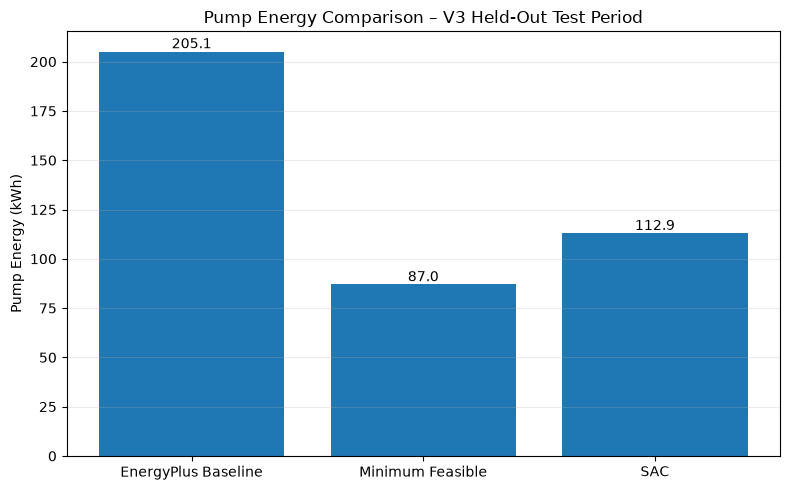

In [33]:
controllers = [
    "EnergyPlus Baseline",
    "Minimum Feasible",
    "SAC",
]

pump_values = [
    baseline_pump,
    minimum_pump,
    sac_pump,
]


fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    controllers,
    pump_values
)

ax.set_ylabel(
    "Pump Energy (kWh)"
)

ax.set_title(
    "Pump Energy Comparison – V3 Held-Out Test Period"
)

ax.grid(
    axis="y",
    alpha=0.25
)


for bar, value in zip(
    bars,
    pump_values
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "pump_energy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 2 — Mean Active CHW Flow

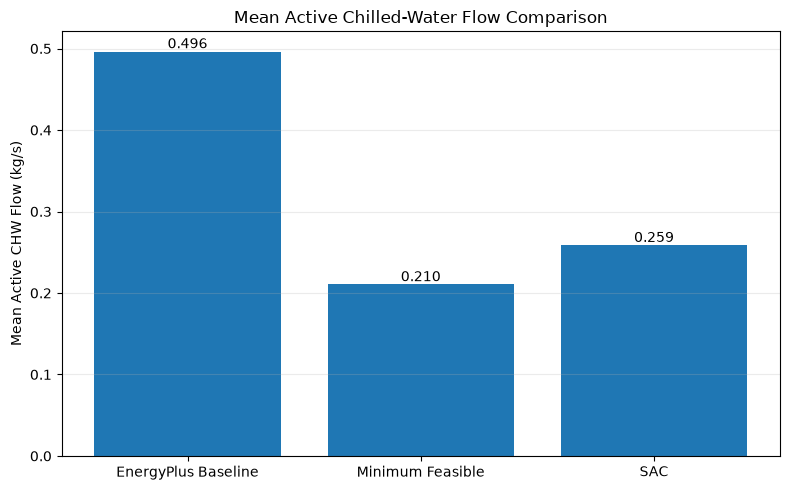

In [34]:
flow_values = [
    baseline_flow,
    minimum_flow,
    sac_flow,
]


fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    controllers,
    flow_values
)

ax.set_ylabel(
    "Mean Active CHW Flow (kg/s)"
)

ax.set_title(
    "Mean Active Chilled-Water Flow Comparison"
)

ax.grid(
    axis="y",
    alpha=0.25
)


for bar, value in zip(
    bars,
    flow_values
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "chw_flow_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 3 — Mean Active ΔT

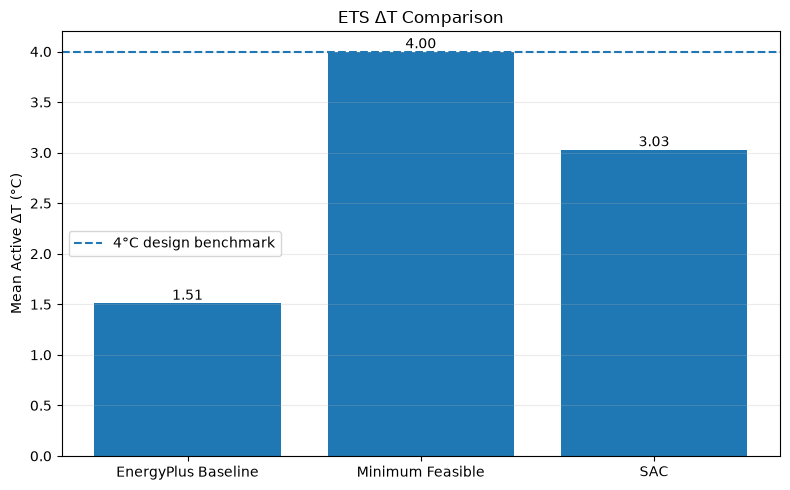

In [35]:
dt_values = [
    baseline_dt,
    minimum_dt,
    sac_dt,
]


fig, ax = plt.subplots(
    figsize=(8, 5)
)

bars = ax.bar(
    controllers,
    dt_values
)

ax.axhline(
    DESIGN_DELTA_T_C,
    linestyle="--",
    linewidth=1.5,
    label="4°C design benchmark"
)

ax.set_ylabel(
    "Mean Active ΔT (°C)"
)

ax.set_title(
    "ETS ΔT Comparison"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)


for bar, value in zip(
    bars,
    dt_values
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )


fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "delta_t_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 4 — Flow Distribution

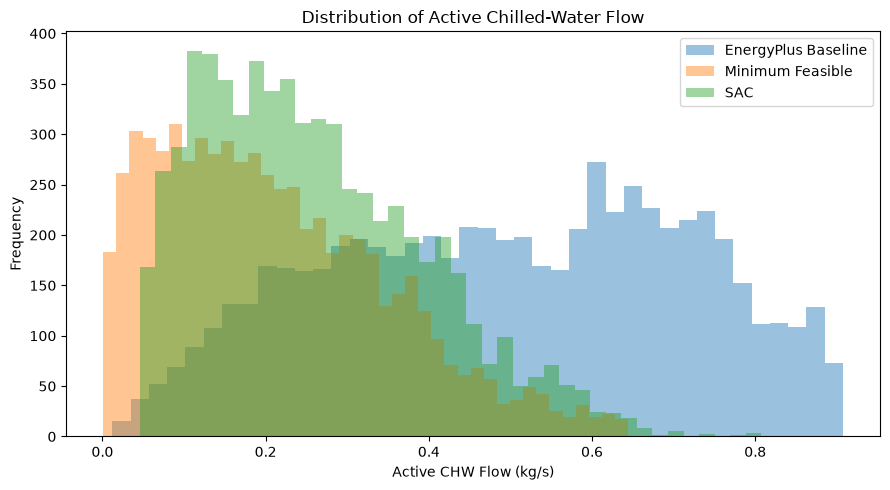

In [36]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.hist(
    baseline_active["flow_kg_s"],
    bins=40,
    alpha=0.45,
    label="EnergyPlus Baseline"
)

ax.hist(
    minimum_active["flow_kg_s"],
    bins=40,
    alpha=0.45,
    label="Minimum Feasible"
)

ax.hist(
    sac_active["flow_kg_s"],
    bins=40,
    alpha=0.45,
    label="SAC"
)

ax.set_xlabel(
    "Active CHW Flow (kg/s)"
)

ax.set_ylabel(
    "Frequency"
)

ax.set_title(
    "Distribution of Active Chilled-Water Flow"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "flow_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 5 — ΔT Distribution

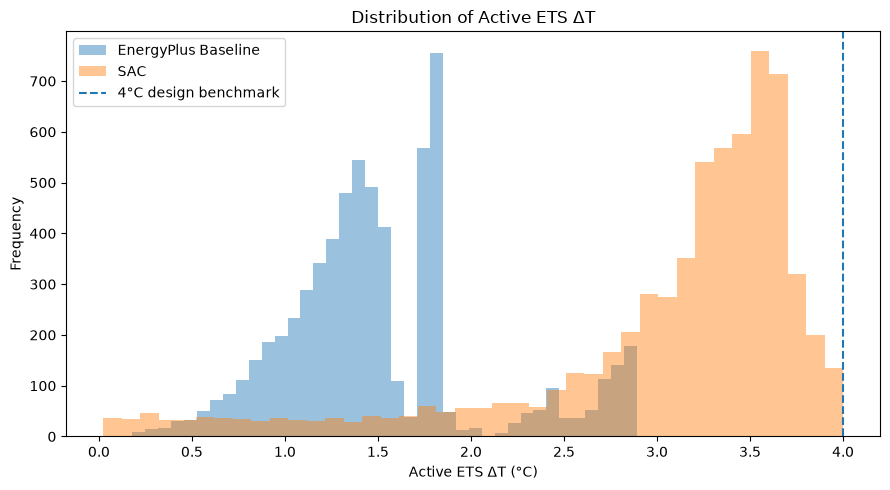

In [37]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.hist(
    baseline_active["delta_t_c"],
    bins=40,
    alpha=0.45,
    label="EnergyPlus Baseline"
)

ax.hist(
    sac_active["delta_t_c"],
    bins=40,
    alpha=0.45,
    label="SAC"
)

ax.axvline(
    DESIGN_DELTA_T_C,
    linestyle="--",
    linewidth=1.5,
    label="4°C design benchmark"
)

ax.set_xlabel(
    "Active ETS ΔT (°C)"
)

ax.set_ylabel(
    "Frequency"
)

ax.set_title(
    "Distribution of Active ETS ΔT"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "delta_t_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 6 — Representative Day: Cooling Requirement

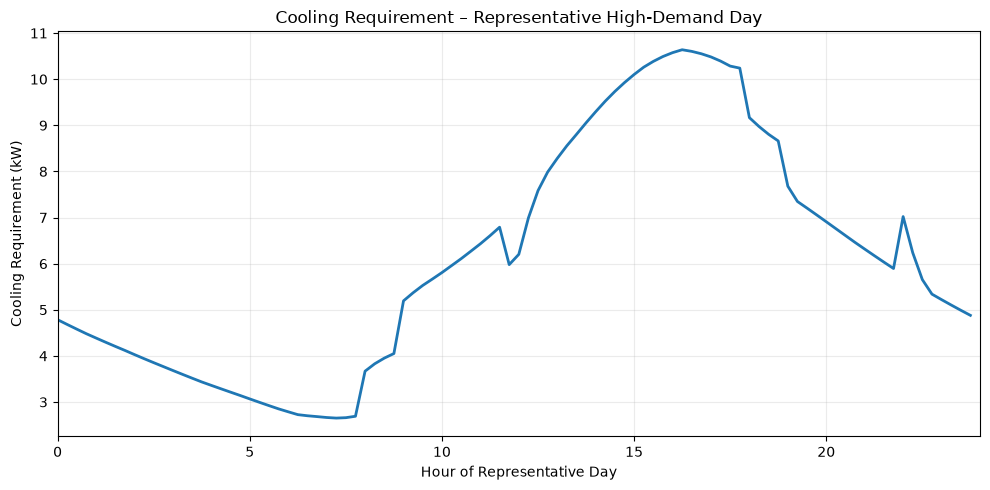

In [38]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    hours,
    baseline_high_day[
        "q_required_w"
    ] / 1000,
    linewidth=2
)

ax.set_xlabel(
    "Hour of Representative Day"
)

ax.set_ylabel(
    "Cooling Requirement (kW)"
)

ax.set_title(
    "Cooling Requirement – Representative High-Demand Day"
)

ax.set_xlim(
    0,
    24
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "representative_day_cooling_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 7 — Representative Day: CHW Flow

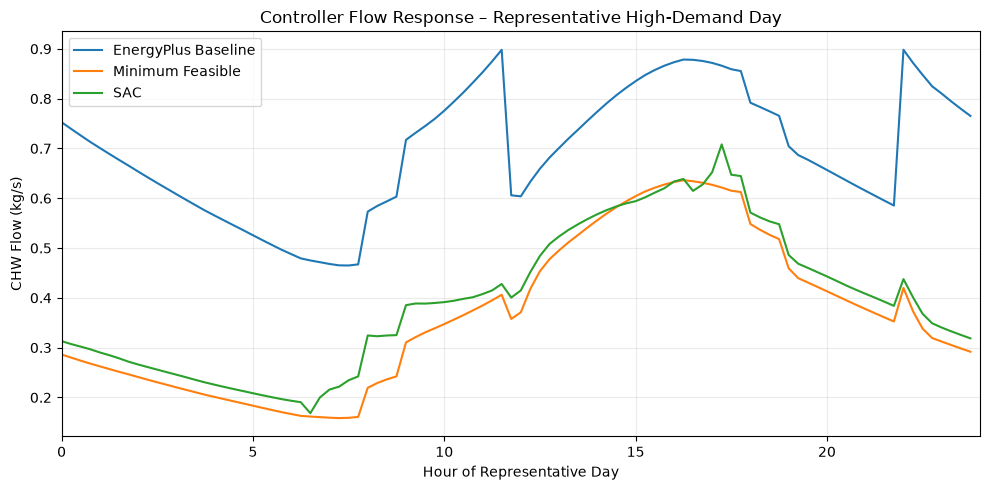

In [39]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    hours,
    baseline_high_day["flow_kg_s"],
    label="EnergyPlus Baseline"
)

ax.plot(
    hours,
    minimum_high_day["flow_kg_s"],
    label="Minimum Feasible"
)

ax.plot(
    hours,
    sac_high_day["flow_kg_s"],
    label="SAC"
)

ax.set_xlabel(
    "Hour of Representative Day"
)

ax.set_ylabel(
    "CHW Flow (kg/s)"
)

ax.set_title(
    "Controller Flow Response – Representative High-Demand Day"
)

ax.set_xlim(
    0,
    24
)

ax.legend()

ax.grid(
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "representative_day_flow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 8 — Representative Day: ΔT

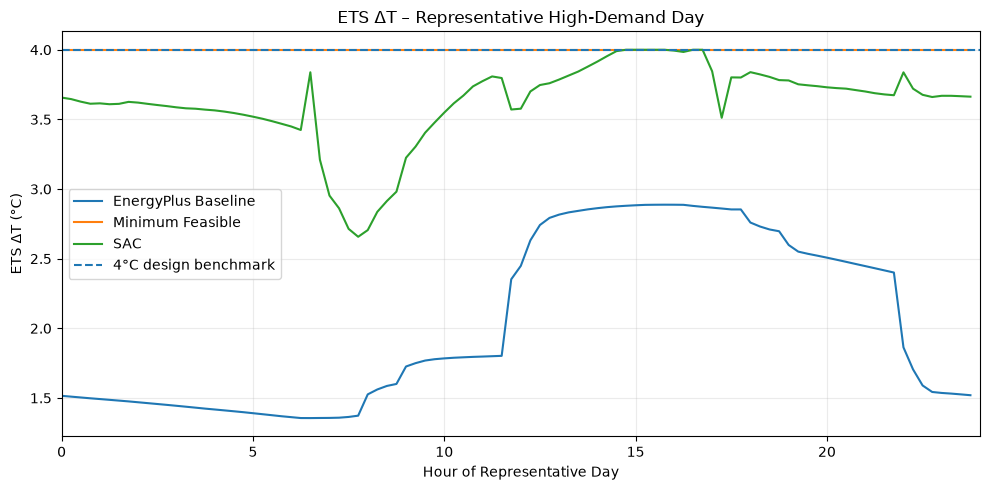

In [40]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    hours,
    baseline_high_day["delta_t_c"],
    label="EnergyPlus Baseline"
)

ax.plot(
    hours,
    minimum_high_day["delta_t_c"],
    label="Minimum Feasible"
)

ax.plot(
    hours,
    sac_high_day["delta_t_c"],
    label="SAC"
)

ax.axhline(
    DESIGN_DELTA_T_C,
    linestyle="--",
    linewidth=1.5,
    label="4°C design benchmark"
)

ax.set_xlabel(
    "Hour of Representative Day"
)

ax.set_ylabel(
    "ETS ΔT (°C)"
)

ax.set_title(
    "ETS ΔT – Representative High-Demand Day"
)

ax.set_xlim(
    0,
    24
)

ax.legend()

ax.grid(
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "representative_day_delta_t.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 9 — Representative Day: Pump Power

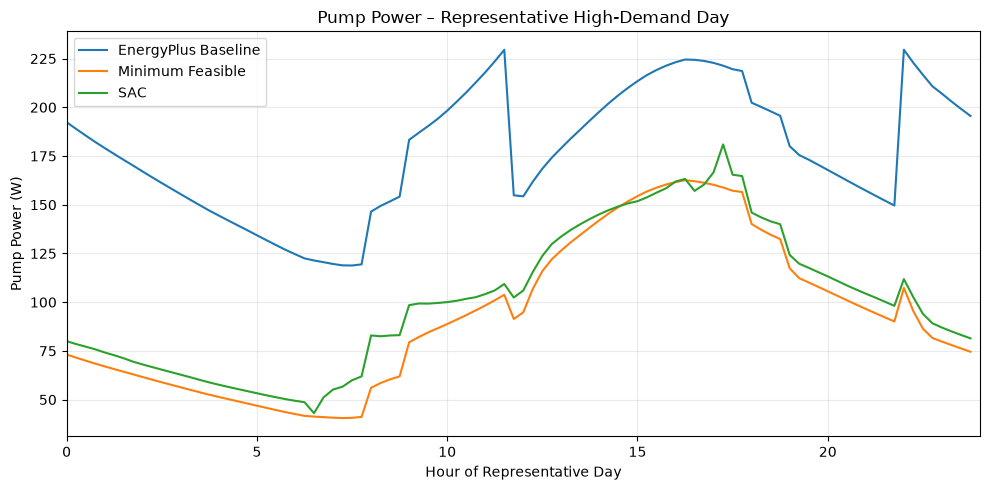

In [41]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    hours,
    baseline_high_day["pump_power_w"],
    label="EnergyPlus Baseline"
)

ax.plot(
    hours,
    minimum_high_day["pump_power_w"],
    label="Minimum Feasible"
)

ax.plot(
    hours,
    sac_high_day["pump_power_w"],
    label="SAC"
)

ax.set_xlabel(
    "Hour of Representative Day"
)

ax.set_ylabel(
    "Pump Power (W)"
)

ax.set_title(
    "Pump Power – Representative High-Demand Day"
)

ax.set_xlim(
    0,
    24
)

ax.legend()

ax.grid(
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "representative_day_pump_power.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 17. Export V3 Benchmark Results

All numerical results, controller time series, summary tables and figures are
exported to the V3 benchmark output directory.

These files provide the reproducible evidence base for the subsequent
dissertation evaluation and comparison with PPO.

Code cell — create folders

In [42]:
DATA_DIR = (
    BENCHMARK_OUTPUT
    / "data"
)

TABLE_DIR = (
    BENCHMARK_OUTPUT
    / "tables"
)

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("Data directory :", DATA_DIR)
print("Table directory:", TABLE_DIR)
print("Figure directory:", FIGURE_DIR)

Data directory : /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/v3_benchmark_output/data
Table directory: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/v3_benchmark_output/tables
Figure directory: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/v3_benchmark_output/figures


Code cell — combined controller dataset

In [43]:
combined_controller_df = pd.concat(
    [
        baseline_df,
        minimum_df,
        sac_df,
    ],
    ignore_index=True
)


baseline_df.to_csv(
    DATA_DIR
    / "energyplus_baseline_timeseries.csv",
    index=False
)

minimum_df.to_csv(
    DATA_DIR
    / "minimum_feasible_timeseries.csv",
    index=False
)

sac_df.to_csv(
    DATA_DIR
    / "sac_timeseries.csv",
    index=False
)

combined_controller_df.to_csv(
    DATA_DIR
    / "controller_timeseries.csv",
    index=False
)


print(
    "Controller time-series files saved."
)

Controller time-series files saved.


Code cell — save tables

In [44]:
kpi_df.to_csv(
    TABLE_DIR
    / "controller_kpi_comparison.csv",
    index=False
)

relative_metrics.to_csv(
    TABLE_DIR
    / "relative_improvements.csv",
    index=False
)

flow_stats.to_csv(
    TABLE_DIR
    / "flow_statistics.csv"
)

dt_stats.to_csv(
    TABLE_DIR
    / "delta_t_statistics.csv"
)

service_summary.to_csv(
    TABLE_DIR
    / "cooling_service_summary.csv",
    index=False
)

daily_load_df.to_csv(
    TABLE_DIR
    / "test_period_daily_cooling.csv",
    index=False
)

high_day_summary.to_csv(
    TABLE_DIR
    / "representative_high_demand_day.csv",
    index=False
)

reproduction_df.to_csv(
    TABLE_DIR
    / "sac_reproduction_validation.csv",
    index=False
)


print(
    "Benchmark tables saved."
)

Benchmark tables saved.


# 18. Final V3 Benchmark Summary

The final V3 benchmark summary consolidates the principal experimental results
into a machine-readable JSON file.

The summary records the held-out test configuration, EnergyPlus baseline,
minimum-feasible engineering benchmark, SAC performance and principal relative
improvements.

These results represent the performance of the trained SAC controller within
the offline physics-based EnergyPlus–ETS environment. They do not constitute
measured building energy savings or a fully interactive closed-loop EnergyPlus
control experiment.

In [45]:
def json_safe(value):

    if isinstance(
        value,
        (np.integer,)
    ):
        return int(value)

    if isinstance(
        value,
        (np.floating,)
    ):
        if np.isnan(value):
            return None
        return float(value)

    if pd.isna(value):
        return None

    return value


def clean_dict(data):

    return {
        key: json_safe(value)
        for key, value in data.items()
    }


v3_final_summary = {

    "experiment": {
        "version":
            "V3",

        "algorithm":
            "Soft Actor-Critic (SAC)",

        "test_start_index":
            TEST_START_INDEX,

        "test_final_index":
            TEST_FINAL_INDEX,

        "test_transitions":
            TEST_STEPS,

        "timestep_hours":
            TIMESTEP_HOURS,

        "active_load_threshold_w":
            ACTIVE_LOAD_W,

        "design_delta_t_c":
            DESIGN_DELTA_T_C,
    },

    "energyplus_baseline":
        clean_dict(
            baseline_summary
        ),

    "minimum_feasible_benchmark":
        clean_dict(
            minimum_summary
        ),

    "sac":
        clean_dict(
            sac_summary
        ),

    "relative_performance": {
        "sac_pump_energy_saving_vs_baseline_pct":
            float(sac_pump_saving),

        "minimum_feasible_pump_energy_saving_vs_baseline_pct":
            float(minimum_pump_saving),

        "sac_pump_energy_above_minimum_feasible_pct":
            float(sac_gap_to_minimum),

        "sac_mean_flow_reduction_vs_baseline_pct":
            float(sac_flow_reduction),

        "minimum_feasible_mean_flow_reduction_vs_baseline_pct":
            float(minimum_flow_reduction),

        "sac_mean_delta_t_increase_vs_baseline_pct":
            float(sac_dt_increase),

        "sac_cooling_delivery_pct":
            float(sac_delivery),
    },

    "representative_high_demand_day": {
        "day_number":
            int(high_day["day_number"]),

        "start_dataset_index":
            int(
                high_day[
                    "start_dataset_index"
                ]
            ),

        "end_dataset_index":
            int(
                high_day[
                    "end_dataset_index"
                ]
            ),

        "cooling_requirement_kwh_th":
            float(
                high_day[
                    "cooling_kwh_th"
                ]
            ),
    },

    "validation": {
        "sac_reproduction":
            "PASS"
    },

    "interpretation_scope": (
        "Offline physics-based EnergyPlus-ETS "
        "controller evaluation. Pump-energy "
        "results are model-estimated secondary "
        "pumping performance and are not measured "
        "closed-loop building energy savings."
    ),
}


SUMMARY_JSON_PATH = (
    BENCHMARK_OUTPUT
    / "v3_benchmark_summary.json"
)


with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        v3_final_summary,
        f,
        indent=2
    )


print(
    "Final summary saved:",
    SUMMARY_JSON_PATH
)

Final summary saved: /Users/ashanperera/EnergyPlus/RL_UAE_HVAC_SOFTWARE/v3_benchmark_output/v3_benchmark_summary.json


# 19. V3 Completion Check

The final cell verifies that the essential V3 benchmark outputs have been
created successfully and that the SAC reproduction test remains valid.

If all checks pass, the SAC implementation, training, held-out evaluation and
benchmarking stages of V3 are considered complete.

In [46]:
required_outputs = [

    DATA_DIR
    / "energyplus_baseline_timeseries.csv",

    DATA_DIR
    / "minimum_feasible_timeseries.csv",

    DATA_DIR
    / "sac_timeseries.csv",

    DATA_DIR
    / "controller_timeseries.csv",

    TABLE_DIR
    / "controller_kpi_comparison.csv",

    TABLE_DIR
    / "relative_improvements.csv",

    TABLE_DIR
    / "flow_statistics.csv",

    TABLE_DIR
    / "delta_t_statistics.csv",

    TABLE_DIR
    / "cooling_service_summary.csv",

    TABLE_DIR
    / "representative_high_demand_day.csv",

    TABLE_DIR
    / "sac_reproduction_validation.csv",

    FIGURE_DIR
    / "pump_energy_comparison.png",

    FIGURE_DIR
    / "chw_flow_comparison.png",

    FIGURE_DIR
    / "delta_t_comparison.png",

    FIGURE_DIR
    / "flow_distribution.png",

    FIGURE_DIR
    / "delta_t_distribution.png",

    FIGURE_DIR
    / "representative_day_cooling_demand.png",

    FIGURE_DIR
    / "representative_day_flow.png",

    FIGURE_DIR
    / "representative_day_delta_t.png",

    FIGURE_DIR
    / "representative_day_pump_power.png",

    SUMMARY_JSON_PATH,
]


missing_outputs = [
    path
    for path in required_outputs
    if not path.exists()
]


assert (
    reproduction_df["Status"]
    == "PASS"
).all(), (
    "SAC reproduction validation failed."
)


assert not missing_outputs, (
    "Missing V3 benchmark outputs:\n"
    + "\n".join(
        str(path)
        for path in missing_outputs
    )
)


print("=" * 70)
print("V3 SAC BENCHMARKING: COMPLETE")
print("=" * 70)

print(
    f"EnergyPlus pump energy : "
    f"{baseline_pump:.4f} kWh"
)

print(
    f"SAC pump energy        : "
    f"{sac_pump:.4f} kWh"
)

print(
    f"SAC pump saving        : "
    f"{sac_pump_saving:.2f}%"
)

print(
    f"SAC cooling delivery   : "
    f"{sac_delivery:.4f}%"
)

print(
    f"Baseline mean ΔT        : "
    f"{baseline_dt:.4f} °C"
)

print(
    f"SAC mean ΔT             : "
    f"{sac_dt:.4f} °C"
)

print(
    f"Minimum benchmark ΔT    : "
    f"{minimum_dt:.4f} °C"
)

print("-" * 70)

print(
    "All V3 benchmark outputs were "
    "generated successfully."
)

print(
    "V3 – SAC implementation, training, "
    "evaluation and benchmarking: COMPLETE"
)

V3 SAC BENCHMARKING: COMPLETE
EnergyPlus pump energy : 205.1301 kWh
SAC pump energy        : 112.9439 kWh
SAC pump saving        : 44.94%
SAC cooling delivery   : 99.9597%
Baseline mean ΔT        : 1.5129 °C
SAC mean ΔT             : 3.0302 °C
Minimum benchmark ΔT    : 4.0000 °C
----------------------------------------------------------------------
All V3 benchmark outputs were generated successfully.
V3 – SAC implementation, training, evaluation and benchmarking: COMPLETE
